# Test: layout of every analysis figure

One figure of **each type** made by the four analysis notebooks (`radiative_forcing`, `bvoc-soa-cloud-interactions`, `biogeophysical-hydro`, `pd-fut-attribution`), with the current `style.py` (Cantarell; math italic DejaVu Sans Oblique) and `forcing_maps.py`.
Purpose: check that every layout is tidy (no overlapping text, enough space between rows, readable numbers) before the analysis notebooks are rerun.
Same calls as the analysis notebooks, but `figdir` = `test_layout_all_figures_outputs/` (`results/figures/` is not touched) and data from the 2001–2009 archive folder (`2001-2009-pre-co2-fix/`).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import matplotlib.pyplot as plt
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
# 2001-2009 processed files were archived on 2026-10-28 (CLAUDE.md, run-version rule step 2 (i))
fm.POSTPROCESSED_DIR = fm.POSTPROCESSED_DIR / "2001-2009-pre-co2-fix"
OUT = Path.cwd() / "test_layout_all_figures_outputs"
OUT.mkdir(exist_ok=True)
years = dict(start_year=2001, end_year=2009)
common = dict(**years, extent_lat=45, mean_lat_min=45, save=True, figdir=OUT)

def show(fig_axes):
    fig, _ = fig_axes
    plt.show(); plt.close(fig)

In [2]:
# tables needed by the budget figures (same as the analysis notebooks; not saved here)
water = fm.water_budget_table(**years)
budget = fm.radiative_budget_table(**years)
chain_lines = {f"{p}: {r['lcc']} − {r['fbvoc']}": (r["lcc"], r["fbvoc"], "#3b75af" if p == "PD" else "#c44e52", "-")
               for p, r in fm.BVOC_PAIRS.items()}
pd_ = fm.BVOC_PAIRS["PD"]
box_lines = {f"{pd_['lcc']} − {pd_['fbvoc']}": (pd_["lcc"], pd_["fbvoc"], "#2a7f62", "-"),
             f"{pd_['lcc']} − {pd_['ctrl']}": (pd_["lcc"], pd_["ctrl"], "#8c6bb1", "--")}

Closure before rounding: Ghan terms vs total 1.1e-07, contrasts 4.4e-04 W m-2


## 1. radiative_forcing: six-panel summary, own colourbars

findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/PD_forcing_decomposition_NET_2001_2009.png


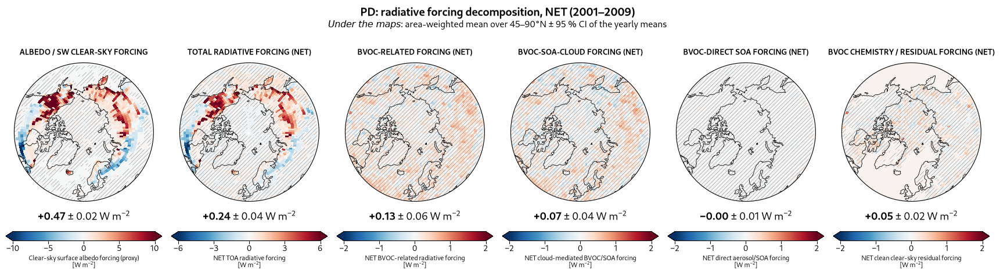

In [3]:
show(fm.make_forcing_summary_figure("PD", band="NET", **common))

## 2. radiative_forcing: six-panel summary, shared6

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/PD_forcing_decomposition_NET_shared6_2001_2009.png


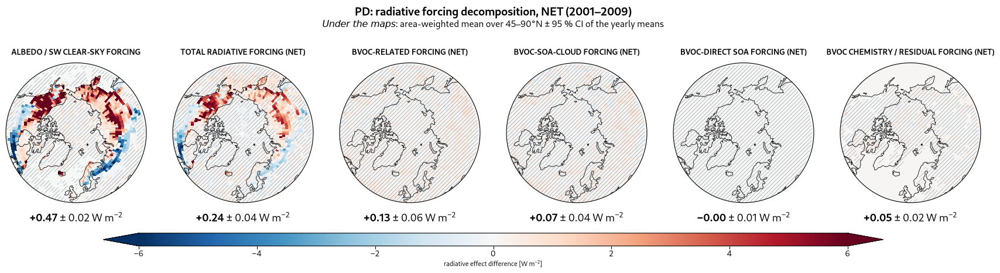

In [4]:
show(fm.make_forcing_summary_figure("PD", band="NET", scales="shared6", **common))

## 3. radiative_forcing: six-panel summary, split6-2

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/PD_forcing_decomposition_NET_split6-2_2001_2009.png


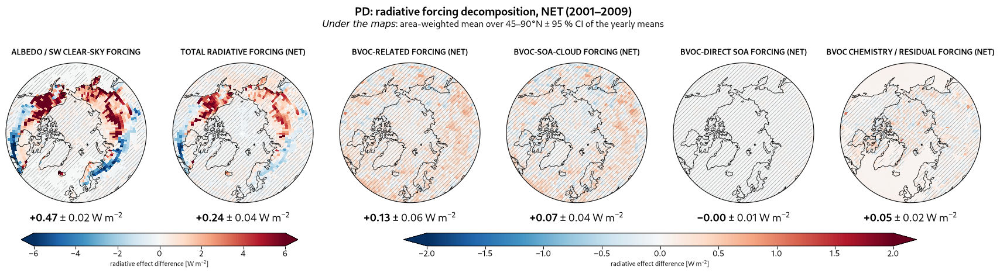

In [5]:
show(fm.make_forcing_summary_figure("PD", band="NET", scales="split6-2", **common))

## 4. radiative_forcing: Ghan, annual

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/PD_ghan_LCC-CTRL_NET_2001_2009.png


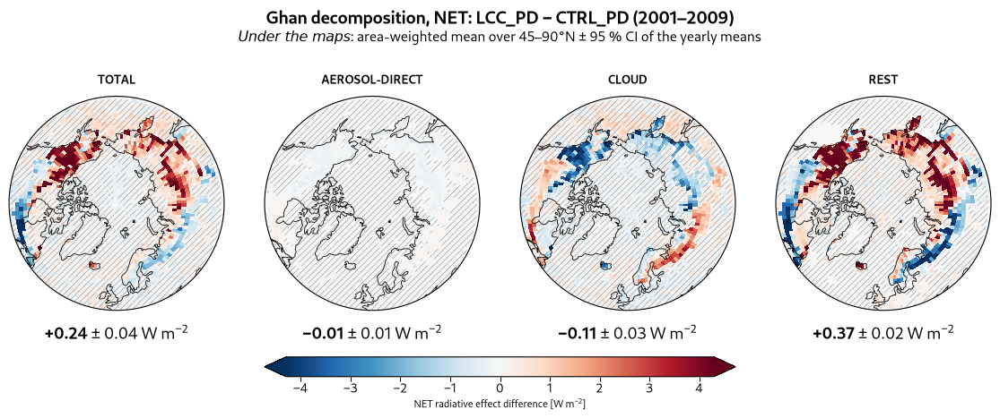

In [6]:
show(fm.make_ghan_figure("PD", "total", "NET", **years, figdir=OUT))

## 5. radiative_forcing: Ghan, seasonal (4 rows)

Ghan closure PD LCC-CTRL NET DJF: max |sum of terms - total| = 2.1e-05 W m-2
Ghan closure PD LCC-CTRL NET MAM: max |sum of terms - total| = 1.8e-05 W m-2
Ghan closure PD LCC-CTRL NET JJA: max |sum of terms - total| = 2.0e-05 W m-2
Ghan closure PD LCC-CTRL NET SON: max |sum of terms - total| = 1.8e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/PD_ghan_seasonal_LCC-CTRL_NET_2001_2009.png


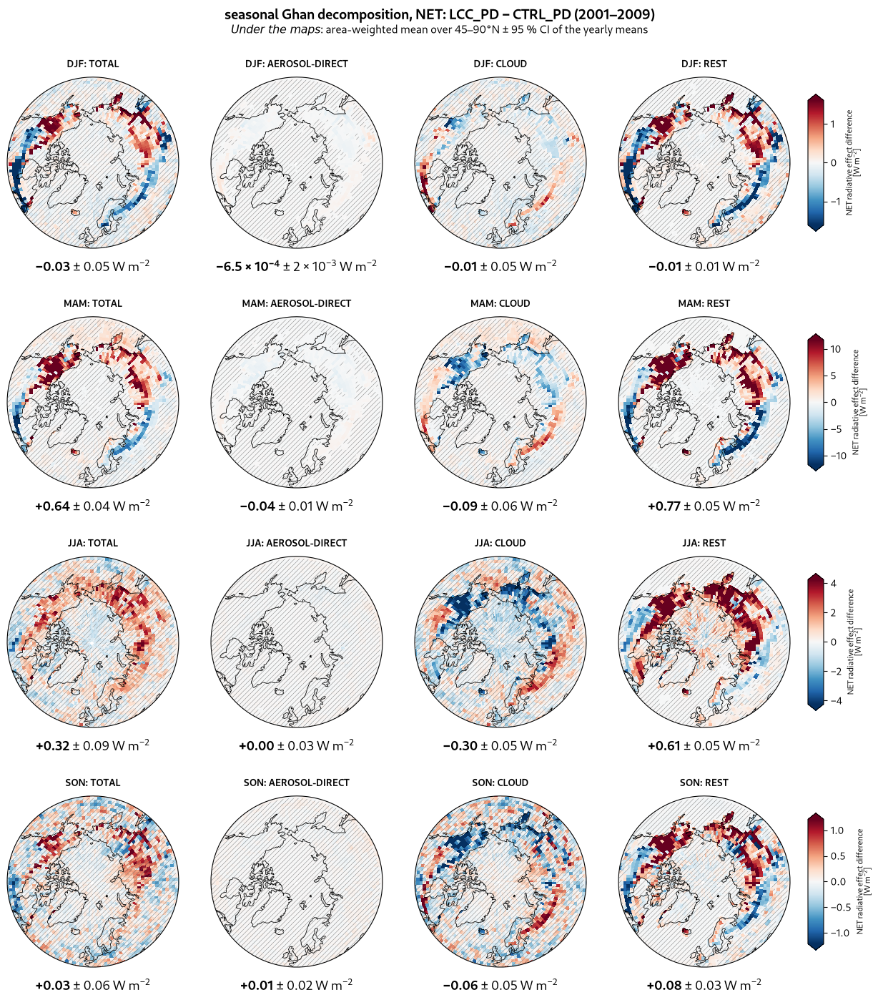

In [7]:
show(fm.make_ghan_figure("PD", "total", "NET", seasonal=True, **years, figdir=OUT))

## 6. bvoc-soa-cloud-interactions: context maps (3 columns)

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/PD_bvoc_context_maps_2001_2009.png


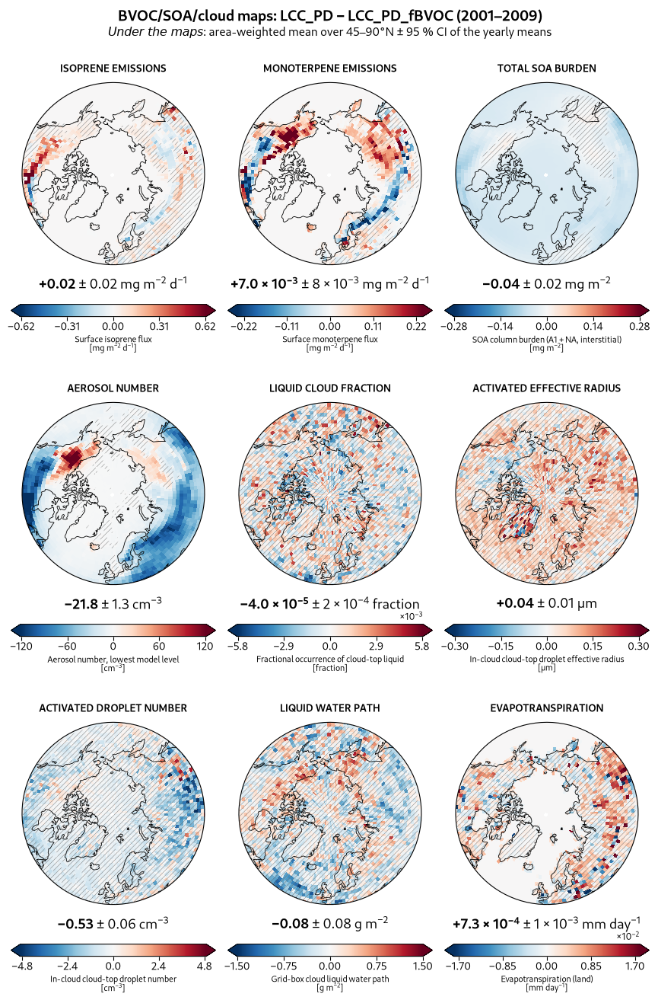

In [8]:
show(fm.make_context_maps_figure("PD", **common))

## 7. bvoc-soa-cloud-interactions: contrast grid, context, LCC-CTRL (4 rows)

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/contrast_grid_context_LCC-CTRL_2001_2009.png


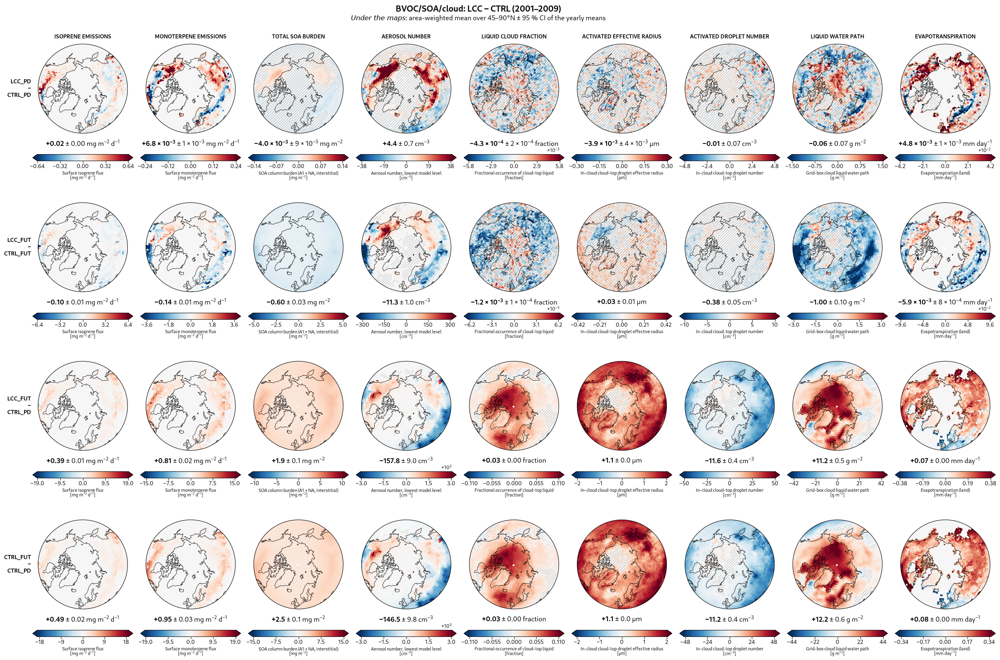

In [9]:
show(fm.make_contrast_grid_figure("LCC-CTRL", fm.CONTEXT_PANELS, "context", **years, figdir=OUT))

## 8. biogeophysical-hydro: contrast grid, hydro, LCC-fBVOC

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/contrast_grid_hydro_LCC-fBVOC_2001_2009.png


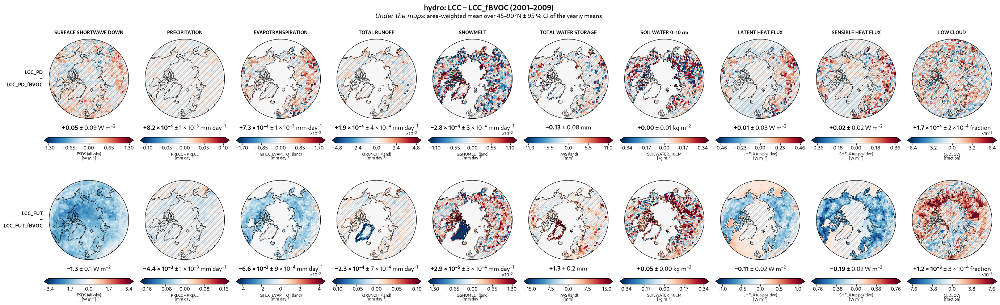

In [10]:
show(fm.make_contrast_grid_figure("LCC-fBVOC", fm.HYDRO_PANELS, "hydro", **years, figdir=OUT))

## 9. biogeophysical-hydro: contrast grid, snow/albedo, LCC-CTRL

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/contrast_grid_snow_albedo_LCC-CTRL_2001_2009.png


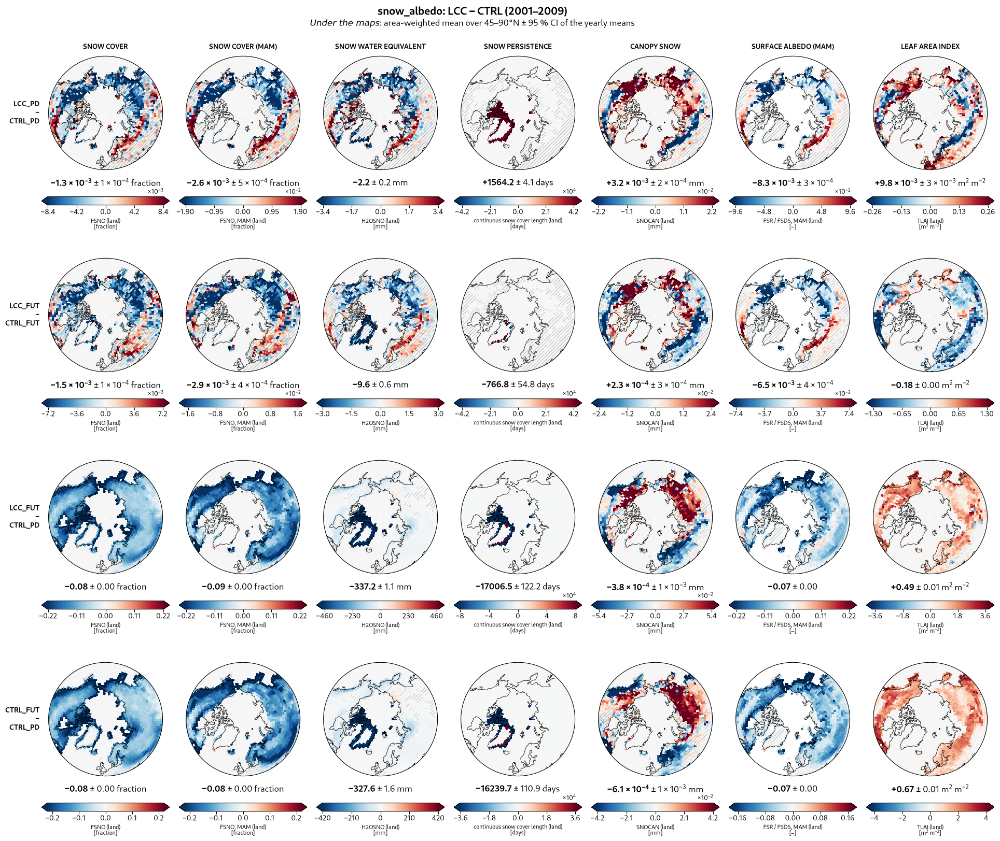

In [11]:
show(fm.make_contrast_grid_figure("LCC-CTRL", fm.SNOW_ALBEDO_PANELS, "snow_albedo", **years, figdir=OUT))

## 10. biogeophysical-hydro: contrast grid, surface energy, fBVOC-CTRL

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/contrast_grid_surface_energy_fBVOC-CTRL_2001_2009.png


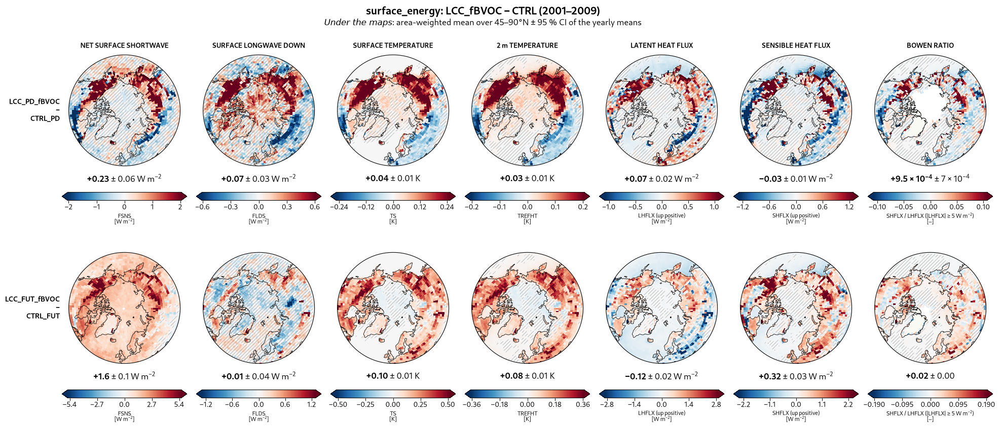

In [12]:
show(fm.make_contrast_grid_figure("fBVOC-CTRL", fm.SURFACE_ENERGY_PANELS, "surface_energy", **years, figdir=OUT))

## 11. biogeophysical-hydro: contrast grid, FSDS split, LCC-fBVOC

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/contrast_grid_fsds_split_LCC-fBVOC_2001_2009.png


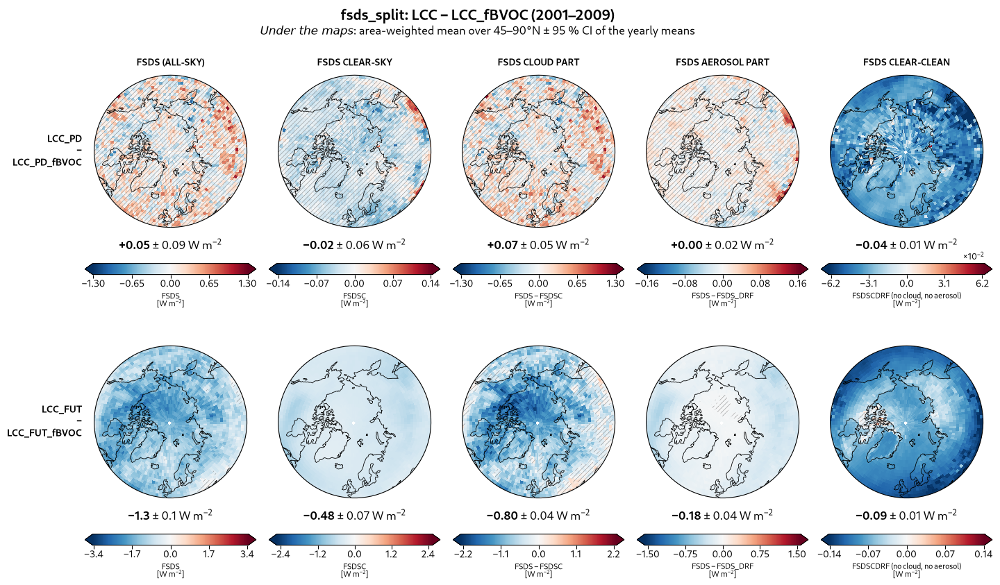

In [13]:
show(fm.make_contrast_grid_figure("LCC-fBVOC", fm.FSDS_SPLIT_PANELS, "fsds_split", **years, figdir=OUT))

## 12. biogeophysical-hydro: water budget, LCC-CTRL

findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/water_budget_LCC-CTRL_2001_2009.png


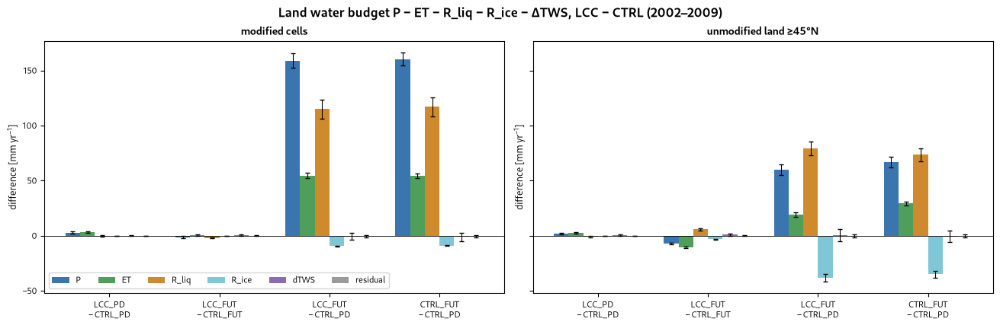

In [14]:
show(fm.make_water_budget_figure(water, "LCC-CTRL", **years, figdir=OUT))

## 13. pd-fut-attribution: radiative budget

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/radiative_budget_3contrasts_2001_2009.png


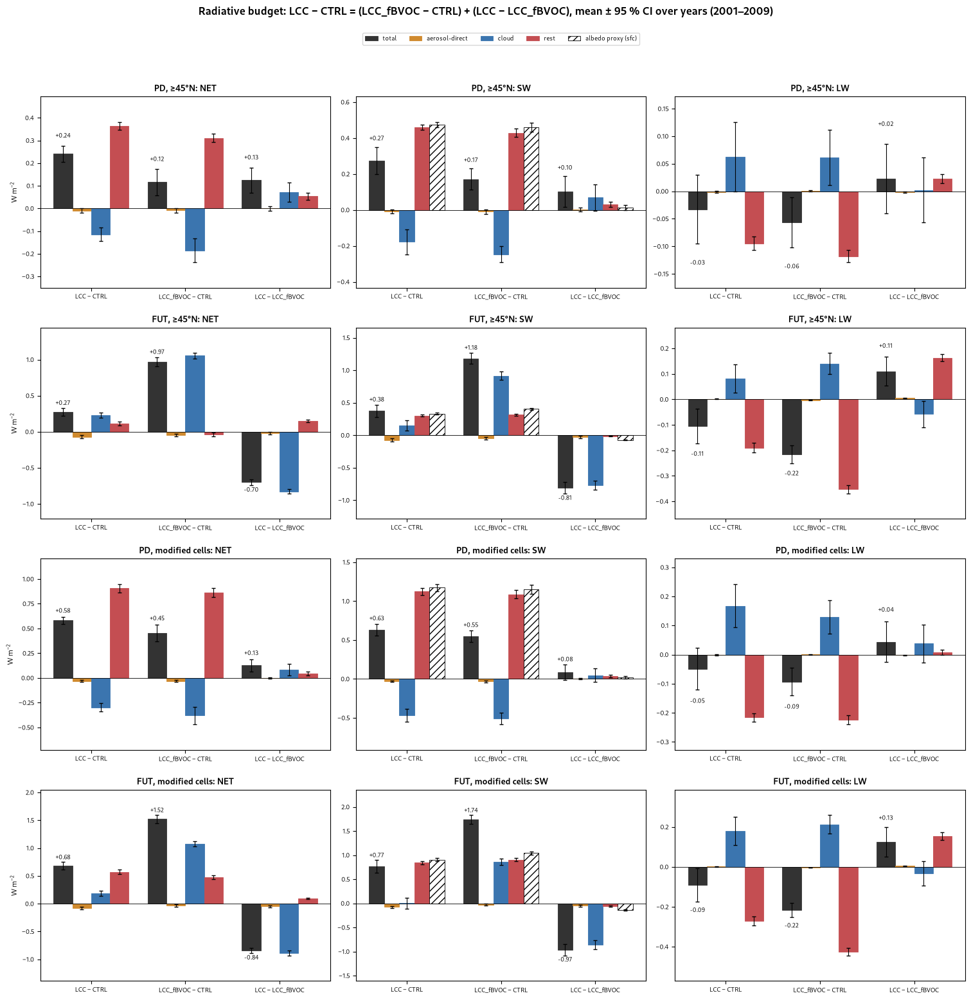

In [15]:
show(fm.make_radiative_budget_figure(budget, **years, figdir=OUT))

## 14. pd-fut-attribution: emission origin

findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/emission_origin_monthly_2001_2009.png


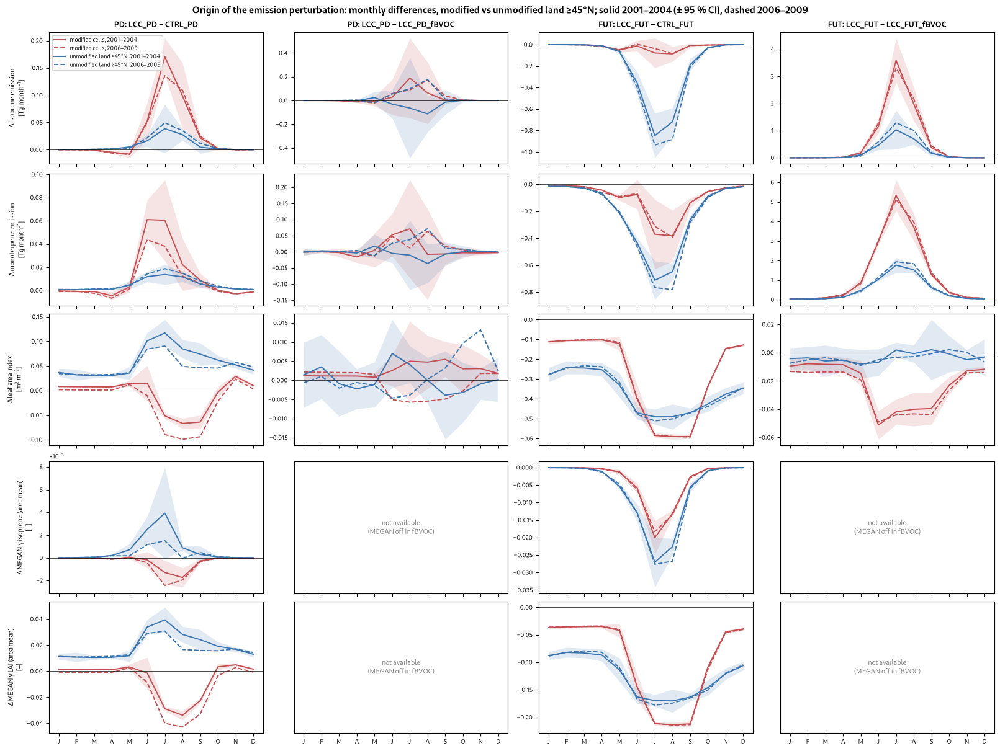

In [16]:
show(fm.make_emission_origin_figure(**years, figdir=OUT))

## 15. pd-fut-attribution: seasonal chain

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/seasonal_chain_bvoc_soa_cloud_sw_2001_2009.png


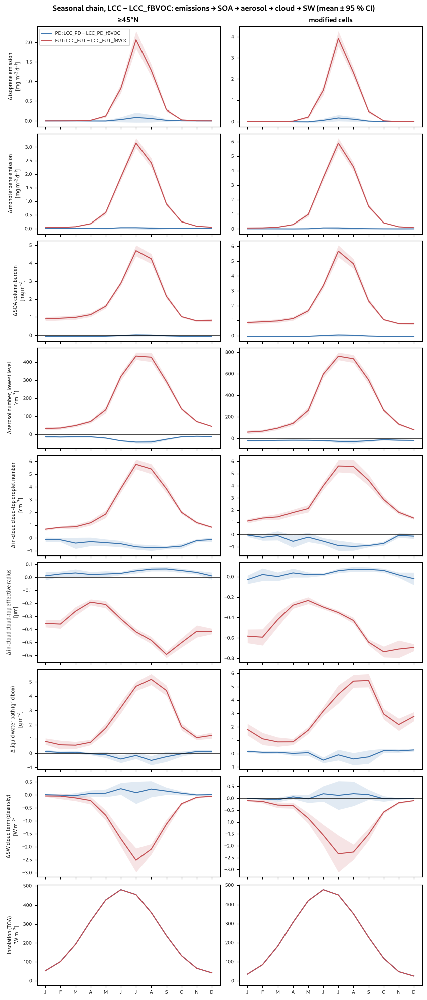

In [17]:
show(fm.make_monthly_chain_figure(
    ["SFISOP", "SFMTERP", "SOA_cb", "N_AER", "ACTNL_incld", "ACTREL_incld", "TGCLDLWP", "SW_cloud"],
    ["≥45°N", "modified cells"], chain_lines, "seasonal_chain_bvoc_soa_cloud_sw",
    "Seasonal chain, LCC − LCC_fBVOC: emissions → SOA → aerosol → cloud → SW (mean ± 95 % CI)",
    context="SOLIN", **years, figdir=OUT))

## 16. pd-fut-attribution: % change maps

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/bvoc_percent_change_maps_2001_2009.png


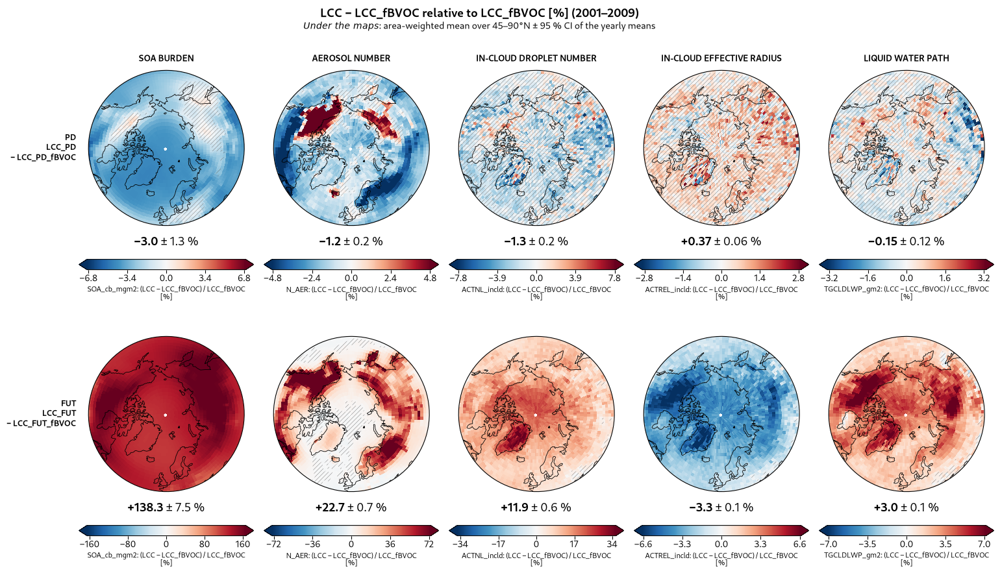

In [18]:
show(fm.make_percent_change_figure(**years, figdir=OUT))

## 17. pd-fut-attribution: paired years, NET

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_layout_all_figures_outputs/paired_years_NET_2001_2009.png


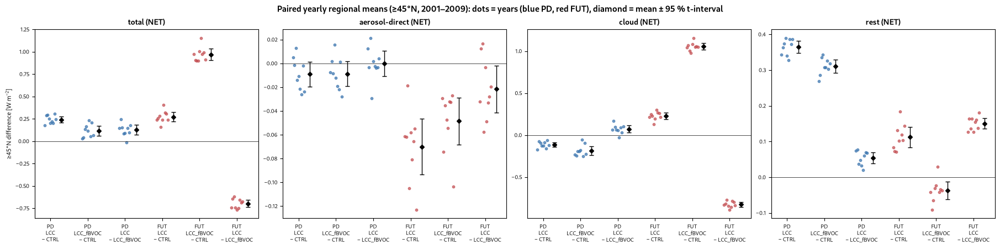

In [19]:
show(fm.make_paired_years_figure(budget, band="NET", **years, figdir=OUT))

## 18. pd-fut-attribution: PD source boxes

RuntimeError: NetCDF: HDF error

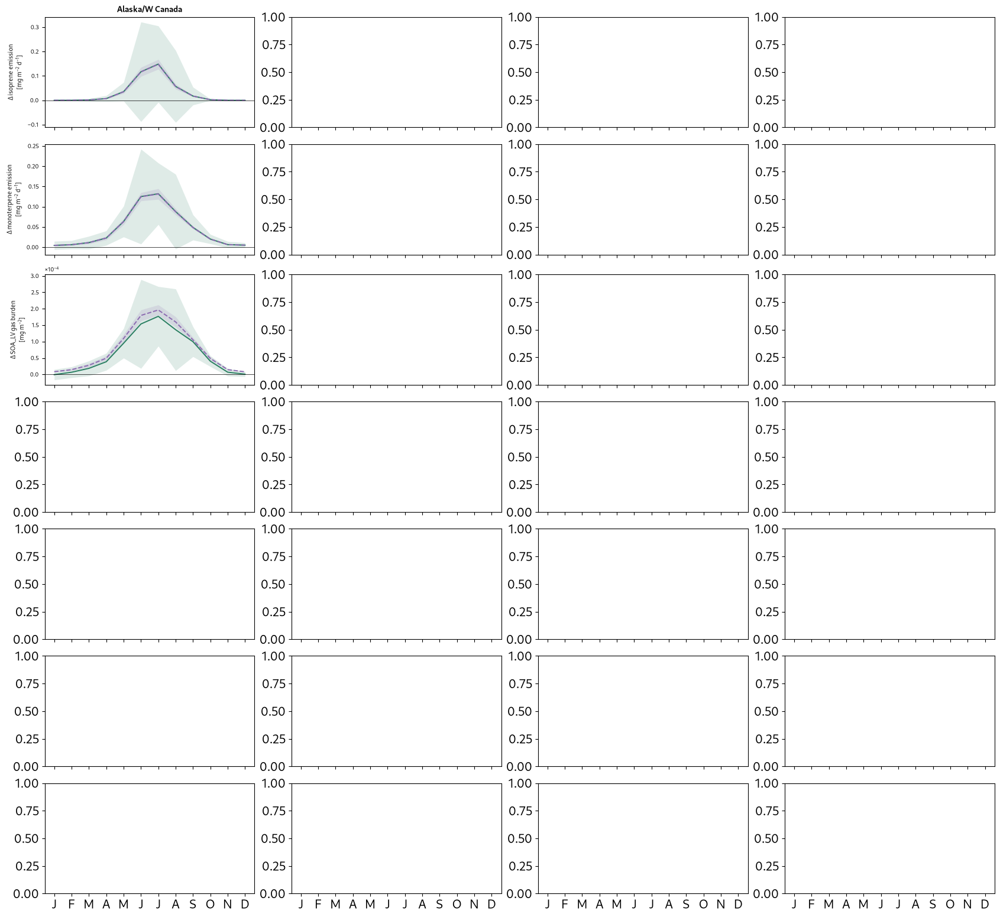

In [20]:
show(fm.make_monthly_chain_figure(
    ["SFISOP", "SFMTERP", "cb_SOA_LV", "cb_SOA_SV", "SOA_cb", "N_AER", "NUCLRATE"],
    list(fm.SOURCE_BOXES), box_lines, "pd_mechanism_source_boxes",
    "PD: monthly precursor, SOA and aerosol differences in four source boxes (mean ± 95 % CI)",
    **years, figdir=OUT, boxes=True))